In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from google.cloud import bigquery
from google.oauth2 import service_account
import google.auth
from pathlib import Path

plt.rcParams.update({
    'figure.figsize': (14, 6),
    'figure.facecolor': 'white',
    'figure.dpi': 100,
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.facecolor': '#F8F9FA',
    'axes.grid': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'grid.color':  '#E0E0E0',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
    'savefig.bbox': 'tight',
    'savefig.dpi': 150,
})

COLORS = {
    'primary':  '#2196F3',
    'secondary': '#FF9800',
    'success':  '#4CAF50',
    'danger': '#F44336',
    'neutral': '#9E9E9E',
    'purple':  '#9C27B0',
    'teal':  '#009688',
}

ALPHA = 0.05

# BIGQUERY CONNECTION
PROJECT_ID = "olist-ecommerce-analytics-1"
CREDENTIALS_PATH  = "../credentials/bigquery-key.json"
MART = f"{PROJECT_ID}.olist_mart"
REPORTING = f"{PROJECT_ID}.olist_reporting"

def get_bq_client(project_id: str) -> bigquery.Client:

    credentials, _ = google.auth.default(
        scopes=["https://www.googleapis.com/auth/cloud-platform"]
    )

    return bigquery.Client(
        project=project_id,
        credentials=credentials,
    )

def run_query(
    client: bigquery.Client,
    query: str,
) -> pd.DataFrame:

    query_job = client.query(query)

    return query_job.result().to_dataframe()

client = get_bq_client(PROJECT_ID)

print("BigQuery client initialized successfully")

BigQuery client initialized successfully


In [2]:
# Fact orders
df = run_query(client, f"""
    SELECT
        order_id,
        customer_unique_id,
        purchase_date,
        purchase_year,
        purchase_month,
        purchase_year_month,
        purchase_day_of_week,
        is_revenue_generating,
        is_ontime_delivery,
        is_order_date_anomaly,
        purchase_to_delivery_days,
        delivery_vs_estimated_days,
        total_gmv,
        total_price,
        total_freight_value,
        item_count,
        primary_payment_type,
        max_installments,
        review_score,
        review_sentiment,
        customer_type
    FROM `{MART}.fact_orders`
    WHERE is_revenue_generating = TRUE
      AND is_order_date_anomaly = FALSE
""")

df['purchase_date'] = pd.to_datetime(df['purchase_date'])

df['is_weekend'] = df['purchase_day_of_week'].isin([1, 7])

df['day_type'] = df['is_weekend'].map({
    True: 'Weekend',
    False: 'Weekday'
})


# Items (delivered)
df_items = run_query(client, f"""
    SELECT
        order_id,
        order_item_id,
        product_category_name_english,
        product_super_category,
        customer_state,
        customer_region,
        seller_state,
        price,
        freight_value,
        item_gmv,
        review_score,
        purchase_to_delivery_days,
        primary_payment_type,
        purchase_year_month
    FROM `{MART}.fact_order_items`
    WHERE is_revenue_generating = TRUE
""")


# Display results
print("Data loaded:")
print(f"fact_orders (delivered): {len(df):,} rows")
print(f"fact_order_items: {len(df_items):,} rows")

print(
    f"Date range: {df['purchase_date'].min().date()} -> "
    f"{df['purchase_date'].max().date()}"
)

Data loaded:
fact_orders (delivered): 95,105 rows
fact_order_items: 110,197 rows
Date range: 2016-09-15 -> 2018-08-29


In [3]:
print("FACT ORDERS:")
print(df[[
    'total_gmv',
    'purchase_to_delivery_days',
    'review_score',
    'max_installments'
]].dtypes)

print("\nFACT ORDER ITEMS:")
print(df_items[[
    'price',
    'freight_value'
]].dtypes)

FACT ORDERS:
total_gmv                    object
purchase_to_delivery_days     Int64
review_score                  Int64
max_installments              Int64
dtype: object

FACT ORDER ITEMS:
price            object
freight_value    object
dtype: object


In [4]:
# Fact Orders
df['total_gmv'] = df['total_gmv'].astype('float64')

# Fact Order Items
df_items['price'] = df_items['price'].astype('float64')
df_items['freight_value'] = df_items['freight_value'].astype('float64')

print("FACT ORDERS:")
print(df[[
    'total_gmv',
    'purchase_to_delivery_days',
    'review_score',
    'max_installments'
]].dtypes)

print("\nFACT ORDER ITEMS:")
print(df_items[[
    'price',
    'freight_value'
]].dtypes)

FACT ORDERS:
total_gmv                    float64
purchase_to_delivery_days      Int64
review_score                   Int64
max_installments               Int64
dtype: object

FACT ORDER ITEMS:
price            float64
freight_value    float64
dtype: object


In [5]:
def descriptive_stats(series: pd.Series, name: str) -> pd.Series:
    s = series.dropna()
    return pd.Series({
        'count': len(s),
        'missing': series.isna().sum(),
        'missing_pct': f"{series.isna().mean()*100:.2f}%",
        'mean': round(s.mean(), 4),
        'median': round(s.median(), 4),
        'mode': round(s.mode().iloc[0], 4) if len(s.mode()) > 0 else np.nan,
        'std': round(s.std(), 4),
        'variance': round(s.var(), 4),
        'min': round(s.min(), 4),
        'p5': round(s.quantile(0.05), 4),
        'p25': round(s.quantile(0.25), 4),
        'p75': round(s.quantile(0.75), 4),
        'p95': round(s.quantile(0.95), 4),
        'max': round(s.max(), 4),
        'IQR': round(s.quantile(0.75) - s.quantile(0.25), 4),
        'skewness': round(stats.skew(s), 4),
        'kurtosis': round(stats.kurtosis(s), 4),
        'cv': f"{s.std()/s.mean()*100:.2f}%" if s.mean() != 0 else 'N/A',
    }, name=name)

metrics = {
    'total_gmv': df['total_gmv'],
    'purchase_to_delivery_days':  df['purchase_to_delivery_days'].dropna(),
    'review_score': df['review_score'].dropna(),
    'max_installments': df['max_installments'].dropna(),
    'item_price': df_items['price'],
    'freight_value': df_items['freight_value'],
}

desc_df = pd.DataFrame({
    name: descriptive_stats(series, name)
    for name, series in metrics.items()
})

print("DESCRIPTIVE STATISTICS SUMMARY")
print(desc_df.T.to_string())

print("\n\nSKEWNESS INTERPRETATION:")
for col in desc_df.columns:
    skew_val = float(desc_df.loc['skewness', col])
    if skew_val > 1:
        interp = "Highly right-skewed"
    elif skew_val > 0.5:
        interp = "Moderately right-skewed"
    elif skew_val < -1:
        interp = "Highly left-skewed"
    elif skew_val < -0.5:
        interp = "Moderately left-skewed"
    else:
        interp = "Approximately symmetric"
    print(f"{col:<35}: {skew_val:>6.3f} => {interp}")

DESCRIPTIVE STATISTICS SUMMARY
                            count missing missing_pct      mean  median   mode       std    variance   min     p5    p25     p75      p95       max    IQR skewness  kurtosis       cv
total_gmv                   95105       0       0.00%  159.9499  105.28  77.57  219.2345  48063.7813  9.59  32.38  61.84  176.34  447.864  13664.08  114.5   9.3895  250.3604  137.06%
purchase_to_delivery_days   95097       0       0.00%   12.5576    10.0      7    9.5804     91.7844     0    3.0    7.0    16.0     29.0       210    9.0   3.8262    39.229   76.29%
review_score                94466       0       0.00%    4.1539     5.0      5    1.2861      1.6541     1    1.0    4.0     5.0      5.0         5    1.0   -1.479    0.9454   30.96%
max_installments            48952       0       0.00%    4.7488     4.0      2    2.7387      7.5005     2    2.0    3.0     6.0     10.0        24    3.0   1.0794    1.1669   57.67%
item_price                 110197       0       0.00% 

NORMALITY TEST RESULTS
        variable  n_total  shapiro_p  shapiro_normal  dagostino_p  dagostino_normal  skewness conclusion                             recommended_test
 Order GMV (BRL)    95105        0.0           False          0.0             False    9.3895 NON-NORMAL Non-parametric (Mann-Whitney/Kruskal-Wallis)
   Delivery Days    95097        0.0           False          0.0             False    3.8262 NON-NORMAL Non-parametric (Mann-Whitney/Kruskal-Wallis)
    Review Score    94466        0.0           False          0.0             False   -1.4790 NON-NORMAL Non-parametric (Mann-Whitney/Kruskal-Wallis)
Item Price (BRL)   110197        0.0           False          0.0             False    8.0308 NON-NORMAL Non-parametric (Mann-Whitney/Kruskal-Wallis)
Max Installments    48952        0.0           False          0.0             False    1.0794 NON-NORMAL Non-parametric (Mann-Whitney/Kruskal-Wallis)


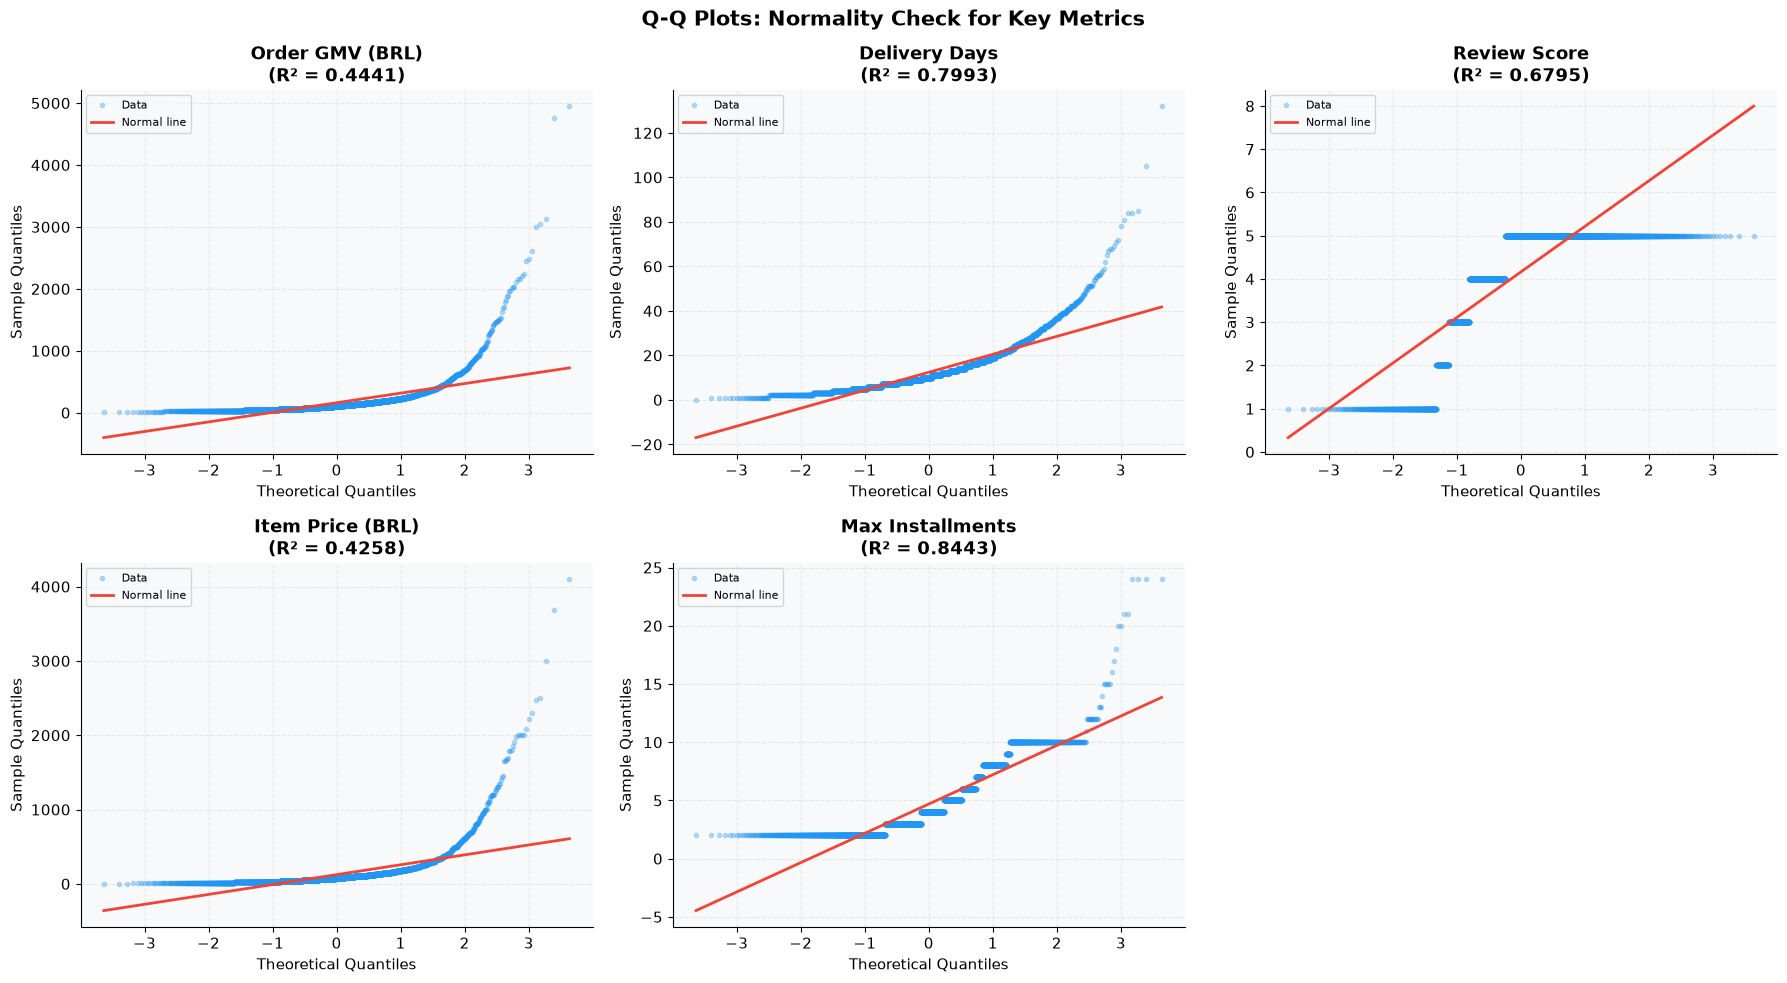

In [6]:
def test_normality(series: pd.Series, name: str,
                   sample_size: int = 5000) -> dict:
    s = series.dropna()

    if len(s) > sample_size:
        s_sample = s.sample(n=sample_size, random_state=42)
    else:
        s_sample = s

    stat_sw, p_sw = stats.shapiro(s_sample)

    stat_dp, p_dp = stats.normaltest(s)

    return {
        'variable': name,
        'n_total': len(s),
        'n_tested': len(s_sample),
        'shapiro_stat': round(stat_sw, 4),
        'shapiro_p':round(p_sw, 6),
        'shapiro_normal': p_sw >= ALPHA,
        'dagostino_stat': round(stat_dp, 4),
        'dagostino_p': round(p_dp, 6),
        'dagostino_normal': p_dp >= ALPHA,
        'skewness': round(stats.skew(s), 4),
        'kurtosis': round(stats.kurtosis(s), 4),
        'conclusion': 'NORMAL' if p_sw >= ALPHA and p_dp >= ALPHA else 'NON-NORMAL',
        'recommended_test': 'Parametric (T-Test/ANOVA)'
                             if p_sw >= ALPHA and p_dp >= ALPHA
                             else 'Non-parametric (Mann-Whitney/Kruskal-Wallis)'
    }


# Uji normalitas
normality_results = []
test_vars = {
    'Order GMV (BRL)': df['total_gmv'],
    'Delivery Days': df['purchase_to_delivery_days'].dropna(),
    'Review Score': df['review_score'].dropna(),
    'Item Price (BRL)': df_items['price'],
    'Max Installments': df['max_installments'].dropna(),
}

for name, series in test_vars.items():
    result = test_normality(series, name)
    normality_results.append(result)

norm_df = pd.DataFrame(normality_results)

print("NORMALITY TEST RESULTS")
print("=" * 80)
cols_show = ['variable', 'n_total', 'shapiro_p', 'shapiro_normal',
             'dagostino_p', 'dagostino_normal', 'skewness', 'conclusion',
             'recommended_test']
print(norm_df[cols_show].to_string(index=False))

# QQ-PLOTS
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Q-Q Plots: Normality Check for Key Metrics',
             fontsize=15, fontweight='bold')
axes = axes.flatten()

for i, (name, series) in enumerate(test_vars.items()):
    ax = axes[i]
    s  = series.dropna()
    if len(s) > 5000:
        s = s.sample(5000, random_state=42)

    (osm, osr), (slope, intercept, r) = stats.probplot(s, dist="norm")
    ax.plot(osm, osr, 'o', color=COLORS['primary'],
            alpha=0.3, markersize=3, label='Data')
    ax.plot(
        [osm.min(), osm.max()],
        [slope * osm.min() + intercept,
         slope * osm.max() + intercept],
        color=COLORS['danger'], linewidth=2, label='Normal line'
    )
    ax.set_title(f'{name}\n(R² = {r**2:.4f})')
    ax.set_xlabel('Theoretical Quantiles')
    ax.set_ylabel('Sample Quantiles')
    ax.legend(fontsize=8)

if len(test_vars) < len(axes):
    for j in range(len(test_vars), len(axes)):
        axes[j].set_visible(False)

plt.tight_layout()
# plt.savefig('../assets/statistical/01_qq_plots.png')
plt.show()

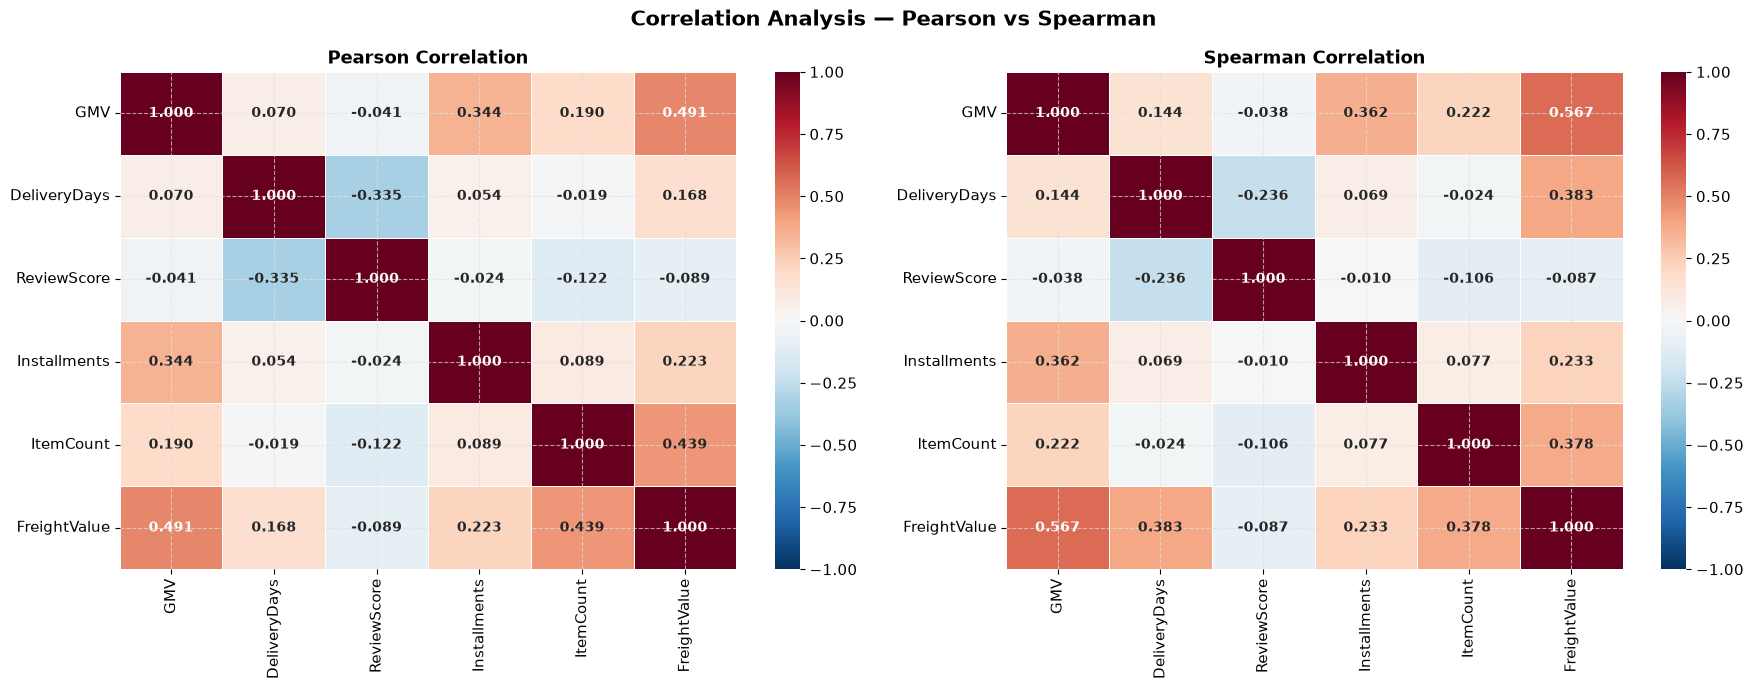

CORRELATION WITH REVIEW SCORE

Variable                Pearson r   Spearman ρ        Strength    Direction      P-value
-------------------------------------------------------------------------------------
DeliveryDays              -0.3352      -0.2361            Weak     Negative            0 ***
   Observations: 94,458
Installments              -0.0243      -0.0102      Negligible     Negative      0.02511 *
   Observations: 48,606
ItemCount                 -0.1220      -0.1060            Weak     Negative   6.319e-234 ***
   Observations: 94,466
GMV                       -0.0412      -0.0384      Negligible     Negative    4.227e-32 ***
   Observations: 94,466
FreightValue              -0.0887      -0.0870      Negligible     Negative    2.95e-158 ***
   Observations: 94,466

Significance: *** p < 0.001 | ** p < 0.01 | * p < 0.05 | ns = not significant


In [7]:
corr_vars = {
    'GMV': df['total_gmv'],
    'DeliveryDays': df['purchase_to_delivery_days'],
    'ReviewScore': df['review_score'],
    'Installments': df['max_installments'],
    'ItemCount': df['item_count'],
    'FreightValue': df['total_freight_value'],
}

corr_df = pd.DataFrame(corr_vars)

corr_df = corr_df.apply(pd.to_numeric, errors='coerce')
corr_df = corr_df.replace([np.inf, -np.inf], np.nan)

pearson_corr = corr_df.corr(method='pearson')
spearman_corr = corr_df.corr(method='spearman')

# HEATMAPS
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

fig.suptitle(
    'Correlation Analysis — Pearson vs Spearman',
    fontsize=15,
    fontweight='bold'
)

heatmap_kws = dict(
    annot=True,
    fmt='.3f',
    linewidths=0.5,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={'size': 10, 'weight': 'bold'}
)

sns.heatmap(pearson_corr, ax=axes[0], **heatmap_kws)
axes[0].set_title('Pearson Correlation')

sns.heatmap(spearman_corr, ax=axes[1], **heatmap_kws)
axes[1].set_title('Spearman Correlation')

plt.tight_layout()
plt.show()


# FOCUS: REVIEW SCORE CORRELATIONS
print("CORRELATION WITH REVIEW SCORE")
print("=" * 85)

print(
    f"\n{'Variable':<20} {'Pearson r':>12} "
    f"{'Spearman ρ':>12} {'Strength':>15} "
    f"{'Direction':>12} {'P-value':>12}"
)

print("-" * 85)

def corr_strength(r):
    """Interpretasi kekuatan korelasi."""

    if pd.isna(r):
        return 'Undefined'

    r_abs = abs(r)

    if r_abs < 0.10:
        return 'Negligible'
    elif r_abs < 0.30:
        return 'Weak'
    elif r_abs < 0.50:
        return 'Moderate'
    elif r_abs < 0.70:
        return 'Strong'
    else:
        return 'Very Strong'


for var in [
    'DeliveryDays',
    'Installments',
    'ItemCount',
    'GMV',
    'FreightValue'
]:

    # Pairwise deletion: memastikan pasangan observasi sama
    pair = corr_df[['ReviewScore', var]].dropna()

    x = pair['ReviewScore']
    y = pair[var]

    p_r, p_p = stats.pearsonr(x, y) if (
        len(pair) >= 3 and x.nunique() > 1 and y.nunique() > 1
    ) else (np.nan, np.nan)

    sp_r, sp_p = stats.spearmanr(x, y) if (
        len(pair) >= 3 and x.nunique() > 1 and y.nunique() > 1
    ) else (np.nan, np.nan)

    direction = (
        'Positive' if sp_r > 0
        else 'Negative' if sp_r < 0
        else 'Undefined'
    ) if pd.notna(sp_r) else 'Undefined'

    strength = corr_strength(sp_r)

    sig = (
        '***' if sp_p < 0.001
        else '**' if sp_p < 0.01
        else '*' if sp_p < 0.05
        else 'ns' if pd.notna(sp_p)
        else 'N/A'
    )

    print(
        f"{var:<20} {p_r:>12.4f} "
        f"{sp_r:>12.4f} {strength:>15} "
        f"{direction:>12} {sp_p:>12.4g} {sig}"
    )

    print(f"   Observations: {len(pair):,}")

print("\nSignificance: *** p < 0.001 | ** p < 0.01 | * p < 0.05 | ns = not significant")



Metric                            Weekend         Weekday
-------------------------------------------------------
n........................          21,862          73,243
Mean (BRL)...............          158.48          160.39
Median (BRL).............          105.39          105.16
Std Dev (BRL)............          216.81          219.95
Min (BRL)................            9.59           10.07
Max (BRL)................        7,274.88       13,664.08
 Statistic: 1.3492
 p-value: 0.245414
 Equal variances: True Using Student's T-Test

TEST RESULTS:
........................................
Independent T-Test:
 t-statistic: -1.1294
 p-value: 0.258726
 Significant: False (α = 0.05)

   Mann-Whitney U (non-parametric confirmation):
 U-statistic: 797666425
 p-value: 0.407170
 Significant: False

 Effect Size (Cohen's d): -0.0087
 Magnitude: Negligible

 95% CI for difference (Weekend - Weekday):
 [-5.19, 1.38] BRL
 Mean difference: -1.91 BRL


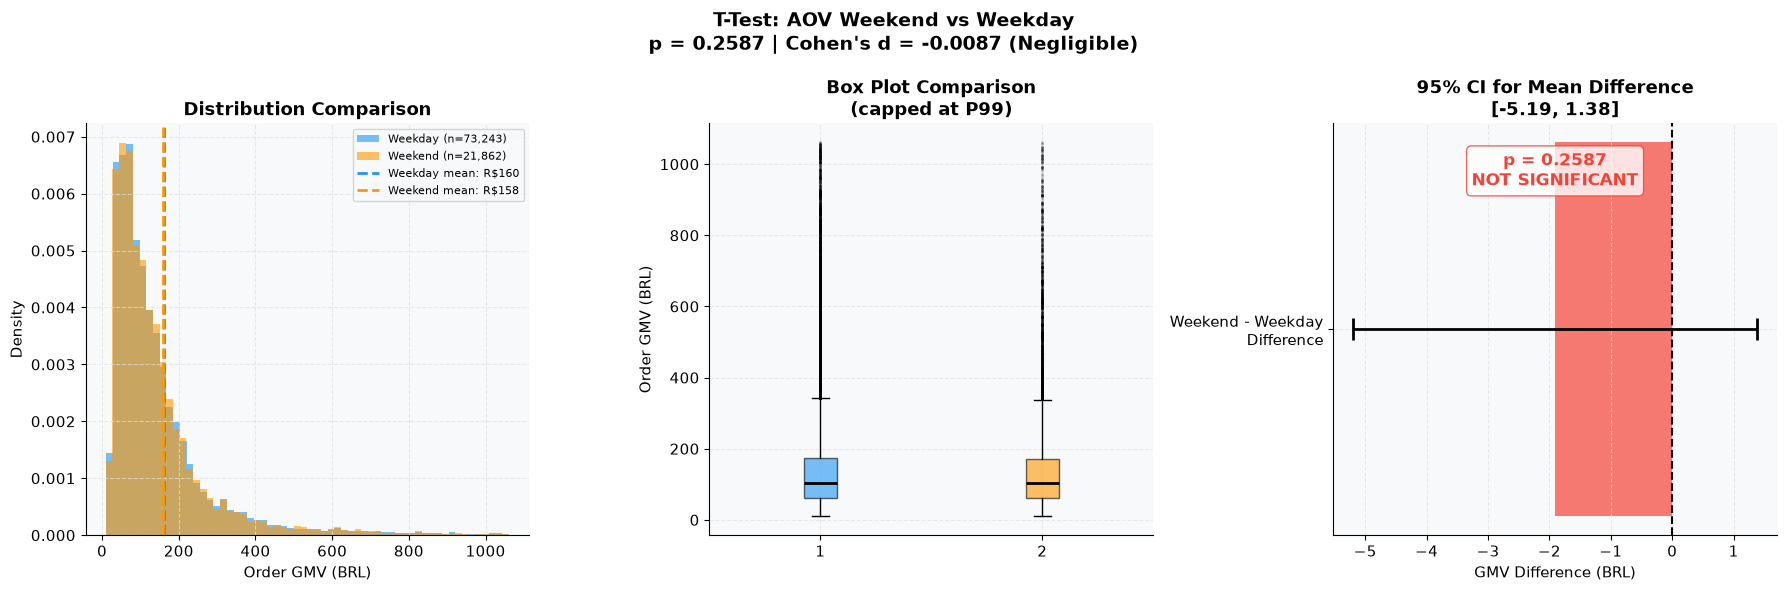

In [ ]:
weekend_gmv = df[df['is_weekend'] == True]['total_gmv'].dropna()
weekday_gmv = df[df['is_weekend'] == False]['total_gmv'].dropna()

# DESCRIPTIVE
print(f"\n{'Metric':<25} {'Weekend':>15} {'Weekday':>15}")
print("-" * 55)
print(f"{'n':.<25} {len(weekend_gmv):>15,} {len(weekday_gmv):>15,}")
print(f"{'Mean (BRL)':.<25} {weekend_gmv.mean():>15,.2f} {weekday_gmv.mean():>15,.2f}")
print(f"{'Median (BRL)':.<25} {weekend_gmv.median():>15,.2f} {weekday_gmv.median():>15,.2f}")
print(f"{'Std Dev (BRL)':.<25} {weekend_gmv.std():>15,.2f} {weekday_gmv.std():>15,.2f}")
print(f"{'Min (BRL)':.<25} {weekend_gmv.min():>15,.2f} {weekday_gmv.min():>15,.2f}")
print(f"{'Max (BRL)':.<25} {weekend_gmv.max():>15,.2f} {weekday_gmv.max():>15,.2f}")

# LEVENE TEST
levene_stat, levene_p = stats.levene(weekend_gmv, weekday_gmv)
equal_var = levene_p >= ALPHA
print(f" Statistic: {levene_stat:.4f}")
print(f" p-value: {levene_p:.6f}")
print(f" Equal variances: {equal_var} "
      f"Using {'Student' if equal_var else 'Welch'}'s T-Test")

# INDEPENDENT T-TEST OR WELCH
t_stat, t_p = stats.ttest_ind(
    weekend_gmv, weekday_gmv,
    equal_var=equal_var,
    alternative='two-sided'
)

# For educational purpose gak masalah untuk coba tentuin lewat levene. tapi defaultnya dan lebih efisien kalo langsung pake welch untuk t-test nya

# MANN-WHITNEY U
mw_stat, mw_p = stats.mannwhitneyu(
    weekend_gmv, weekday_gmv,
    alternative='two-sided'
)

# COHEN'S D
def cohens_d(group1: pd.Series, group2: pd.Series) -> float:
    n1, n2   = len(group1), len(group2)
    mean_diff = group1.mean() - group2.mean()
    # Pooled std
    pooled_std = np.sqrt(
        ((n1 - 1) * group1.std()**2 + (n2 - 1) * group2.std()**2)
        / (n1 + n2 - 2)
    )
    return mean_diff / pooled_std

d = cohens_d(weekend_gmv, weekday_gmv)

def interpret_cohens_d(d: float) -> str:
    """Interpretasi magnitude Cohen's d."""
    d_abs = abs(d)
    if d_abs < 0.2:  return 'Negligible'
    elif d_abs < 0.5: return 'Small'
    elif d_abs < 0.8: return 'Medium'
    else: return 'Large'

# 95% CONFIDENCE INTERVAL
mean_diff = weekend_gmv.mean() - weekday_gmv.mean()
se_diff   = np.sqrt(
    weekend_gmv.std()**2 / len(weekend_gmv) +
    weekday_gmv.std()**2 / len(weekday_gmv)
)
# Critical t-value for 95% CI
df_ttest = min(len(weekend_gmv), len(weekday_gmv)) - 1
t_crit   = stats.t.ppf(0.975, df=df_ttest)
ci_lower = mean_diff - t_crit * se_diff
ci_upper = mean_diff + t_crit * se_diff

# PRINT RESULTS
print(f"\nTEST RESULTS:")
print(f"{'':.<40}")
print(f"Independent T-Test:")
print(f" t-statistic: {t_stat:.4f}")
print(f" p-value: {t_p:.6f}")
print(f" Significant: {t_p < ALPHA} (α = {ALPHA})")
print(f"\n   Mann-Whitney U (non-parametric confirmation):")
print(f" U-statistic: {mw_stat:.0f}")
print(f" p-value: {mw_p:.6f}")
print(f" Significant: {mw_p < ALPHA}")
print(f"\n Effect Size (Cohen's d): {d:.4f}")
print(f" Magnitude: {interpret_cohens_d(d)}")
print(f"\n 95% CI for difference (Weekend - Weekday):")
print(f" [{ci_lower:,.2f}, {ci_upper:,.2f}] BRL")
print(f" Mean difference: {mean_diff:,.2f} BRL")

# VISUALIZATION
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    f'T-Test: AOV Weekend vs Weekday\n'
    f'p = {t_p:.4f} | Cohen\'s d = {d:.4f} ({interpret_cohens_d(d)})',
    fontsize=14, fontweight='bold'
)

# Plot 1: Distribution comparison
ax1 = axes[0]
p99 = max(weekend_gmv.quantile(0.99), weekday_gmv.quantile(0.99))
ax1.hist(weekday_gmv[weekday_gmv <= p99], bins=60, alpha=0.6,
         color=COLORS['primary'], label=f'Weekday (n={len(weekday_gmv):,})',
         density=True)
ax1.hist(weekend_gmv[weekend_gmv <= p99], bins=60, alpha=0.6,
         color=COLORS['secondary'], label=f'Weekend (n={len(weekend_gmv):,})',
         density=True)
ax1.axvline(weekday_gmv.mean(), color=COLORS['primary'],
            linestyle='--', linewidth=2,
            label=f'Weekday mean: R${weekday_gmv.mean():.0f}')
ax1.axvline(weekend_gmv.mean(), color=COLORS['secondary'],
            linestyle='--', linewidth=2,
            label=f'Weekend mean: R${weekend_gmv.mean():.0f}')
ax1.set_xlabel('Order GMV (BRL)')
ax1.set_ylabel('Density')
ax1.set_title('Distribution Comparison')
ax1.legend(fontsize=8)

# Plot 2: Box plots
ax2 = axes[1]
bp = ax2.boxplot(
    [weekday_gmv[weekday_gmv <= p99],
     weekend_gmv[weekend_gmv <= p99]],
    label=['Weekday', 'Weekend'],
    patch_artist=True,
    medianprops=dict(color='black', linewidth=2),
    flierprops=dict(marker='.', markersize=2, alpha=0.2)
)
bp['boxes'][0].set_facecolor(COLORS['primary'])
bp['boxes'][1].set_facecolor(COLORS['secondary'])
for box in bp['boxes']:
    box.set_alpha(0.6)
ax2.set_ylabel('Order GMV (BRL)')
ax2.set_title('Box Plot Comparison\n(capped at P99)')

# Plot 3: Confidence interval for difference
ax3 = axes[2]
ax3.barh(
    ['Weekend - Weekday\nDifference'],
    [mean_diff],
    xerr=[[mean_diff - ci_lower], [ci_upper - mean_diff]],
    color=COLORS['success'] if mean_diff > 0 else COLORS['danger'],
    alpha=0.7, capsize=8, height=0.4,
    error_kw=dict(linewidth=2, capthick=2)
)
ax3.axvline(0, color='black', linewidth=1.5, linestyle='--')
ax3.set_xlabel('GMV Difference (BRL)')
ax3.set_title(f'95% CI for Mean Difference\n[{ci_lower:.2f}, {ci_upper:.2f}]')

# Annotation
significance = "SIGNIFICANT" if t_p < ALPHA else "NOT SIGNIFICANT"
color_sig    = COLORS['success'] if t_p < ALPHA else COLORS['danger']
ax3.text(
    0.5, 0.85,
    f"p = {t_p:.4f}\n{significance}",
    transform=ax3.transAxes,
    ha='center', fontsize=12, fontweight='bold', color=color_sig,
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor=color_sig)
)

plt.tight_layout()
# plt.savefig('../assets/statistical/03_ttest_aov_weekend_weekday.png')
plt.show()


Metric                         On-Time         Late
--------------------------------------------------
n........................       86,830        7,628
Mean.....................       4.2936       2.5631
Median...................          5.0          2.0
Std Dev..................       1.1472       1.6582

MANN-WHITNEY U TEST RESULTS:
 U-statistic: 514656116
 p-value: 0.0000000000
 Significant: True
 Effect size r: -0.5541 (Large)


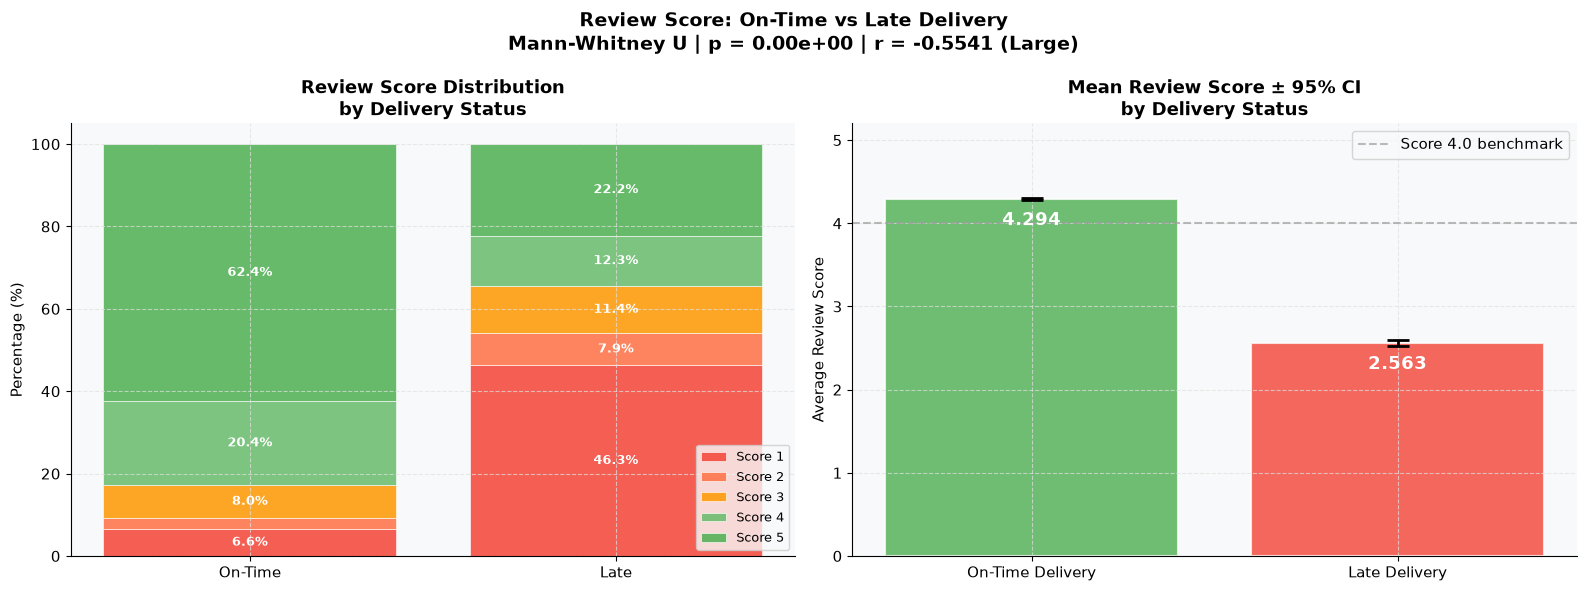

On-time orders: avg score = 4.294
Late orders: avg score = 2.563
Difference: 1.731 points

   Effect size r = -0.5541 => Large


In [18]:
on_time  = df[df['is_ontime_delivery'] == True]['review_score'].dropna()
late_del = df[df['is_ontime_delivery'] == False]['review_score'].dropna()

# Descriptive
print(f"\n{'Metric':<25} {'On-Time':>12} {'Late':>12}")
print("-" * 50)
print(f"{'n':.<25} {len(on_time):>12,} {len(late_del):>12,}")
print(f"{'Mean':.<25} {on_time.mean():>12.4f} {late_del.mean():>12.4f}")
print(f"{'Median':.<25} {on_time.median():>12.1f} {late_del.median():>12.1f}")
print(f"{'Std Dev':.<25} {on_time.std():>12.4f} {late_del.std():>12.4f}")

# Mann-Whitney U Test
mw_stat, mw_p = stats.mannwhitneyu(
    on_time, late_del, alternative='greater'
)

# Effect size:
n1, n2 = len(on_time), len(late_del)
r_effect = 1 - (2 * mw_stat) / (n1 * n2)

def interpret_r_effect(r: float) -> str:
    r_abs = abs(r)
    if r_abs < 0.10: return 'Negligible'
    elif r_abs < 0.30: return 'Small'
    elif r_abs < 0.50: return 'Medium'
    else: return 'Large'

print(f"\nMANN-WHITNEY U TEST RESULTS:")
print(f" U-statistic: {mw_stat:.0f}")
print(f" p-value: {mw_p:.10f}")
print(f" Significant: {mw_p < ALPHA}")
print(f" Effect size r: {r_effect:.4f} ({interpret_r_effect(r_effect)})")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    f'Review Score: On-Time vs Late Delivery\n'
    f'Mann-Whitney U | p = {mw_p:.2e} | r = {r_effect:.4f} '
    f'({interpret_r_effect(r_effect)})',
    fontsize=14, fontweight='bold'
)

# Plot 1: Stacked bar — score distribution per delivery type
ax1 = axes[0]
score_dist = pd.DataFrame({
    'On-Time':  on_time.value_counts(normalize=True).sort_index() * 100,
    'Late':     late_del.value_counts(normalize=True).sort_index() * 100
}).fillna(0)

score_colors_map = {1: '#F44336', 2: '#FF7043', 3: '#FF9800',
                    4: '#66BB6A', 5: '#4CAF50'}
x_pos = np.arange(2)
bottoms = np.zeros(2)
labels = ['On-Time', 'Late']

for score in [1, 2, 3, 4, 5]:
    heights = [
        score_dist.loc[score, 'On-Time'] if score in score_dist.index else 0,
        score_dist.loc[score, 'Late'] if score in score_dist.index else 0
    ]
    bars = ax1.bar(x_pos, heights, bottom=bottoms,
                   color=score_colors_map[score], alpha=0.85,
                   edgecolor='white', linewidth=0.5,
                   label=f'Score {score}')
    # Annotate if large enough
    for i, (h, b) in enumerate(zip(heights, bottoms)):
        if h > 5:
            ax1.text(i, b + h/2, f'{h:.1f}%',
                     ha='center', va='center',
                     fontsize=9, fontweight='bold', color='white')
    bottoms += np.array(heights)

ax1.set_xticks(x_pos)
ax1.set_xticklabels(labels)
ax1.set_ylabel('Percentage (%)')
ax1.set_title('Review Score Distribution\nby Delivery Status')
ax1.legend(loc='lower right', fontsize=9)

# Plot 2: Mean review score comparison
ax2 = axes[1]
means = [on_time.mean(), late_del.mean()]
sems  = [
    stats.sem(on_time),
    stats.sem(late_del)
]
colors = [COLORS['success'], COLORS['danger']]
bars = ax2.bar(
    ['On-Time Delivery', 'Late Delivery'],
    means, yerr=[1.96*s for s in sems],
    color=colors, alpha=0.8, capsize=8,
    edgecolor='white', linewidth=1.5,
    error_kw=dict(linewidth=2, capthick=2)
)
for bar, mean in zip(bars, means):
    ax2.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() - 0.15,
        f'{mean:.3f}', ha='center', va='top',
        fontsize=13, fontweight='bold', color='white'
    )

ax2.set_ylabel('Average Review Score')
ax2.set_title('Mean Review Score ± 95% CI\nby Delivery Status')
ax2.set_ylim(0, 5.2)
ax2.axhline(
    4.0, color=COLORS['neutral'],
    linestyle='--', linewidth=1.5, alpha=0.7,
    label='Score 4.0 benchmark'
)
ax2.legend()

plt.tight_layout()
# plt.savefig('../assets/statistical/04_mann_whitney_review_delivery.png')
plt.show()

print(f"On-time orders: avg score = {on_time.mean():.3f}")
print(f"Late orders: avg score = {late_del.mean():.3f}")
print(f"Difference: {on_time.mean() - late_del.mean():.3f} points")
print(f"\n   Effect size r = {r_effect:.4f} => {interpret_r_effect(r_effect)}")

ANOVA + KRUSKAL-WALLIS: Review Score by Product Category

Category                                       n    Mean   Median     Std
----------------------------------------------------------------------
   health_beauty                            9,402   4.189      5.0   1.289
   sports_leisure                           8,378   4.165      5.0   1.300
   auto                                     4,099   4.115      5.0   1.312
   housewares                               6,756   4.106      5.0   1.329
   garden_tools                             4,240   4.084      5.0   1.357
   watches_gifts                            5,815   4.072      5.0   1.347
   telephony                                4,404   3.994      5.0   1.352
   computers_accessories                    7,608   3.987      5.0   1.410
   furniture_decor                          8,080   3.953      5.0   1.431
   bed_bath_table                          10,831   3.924      5.0   1.428

 STATISTICAL TEST RESULTS:

   One-Way ANOVA:


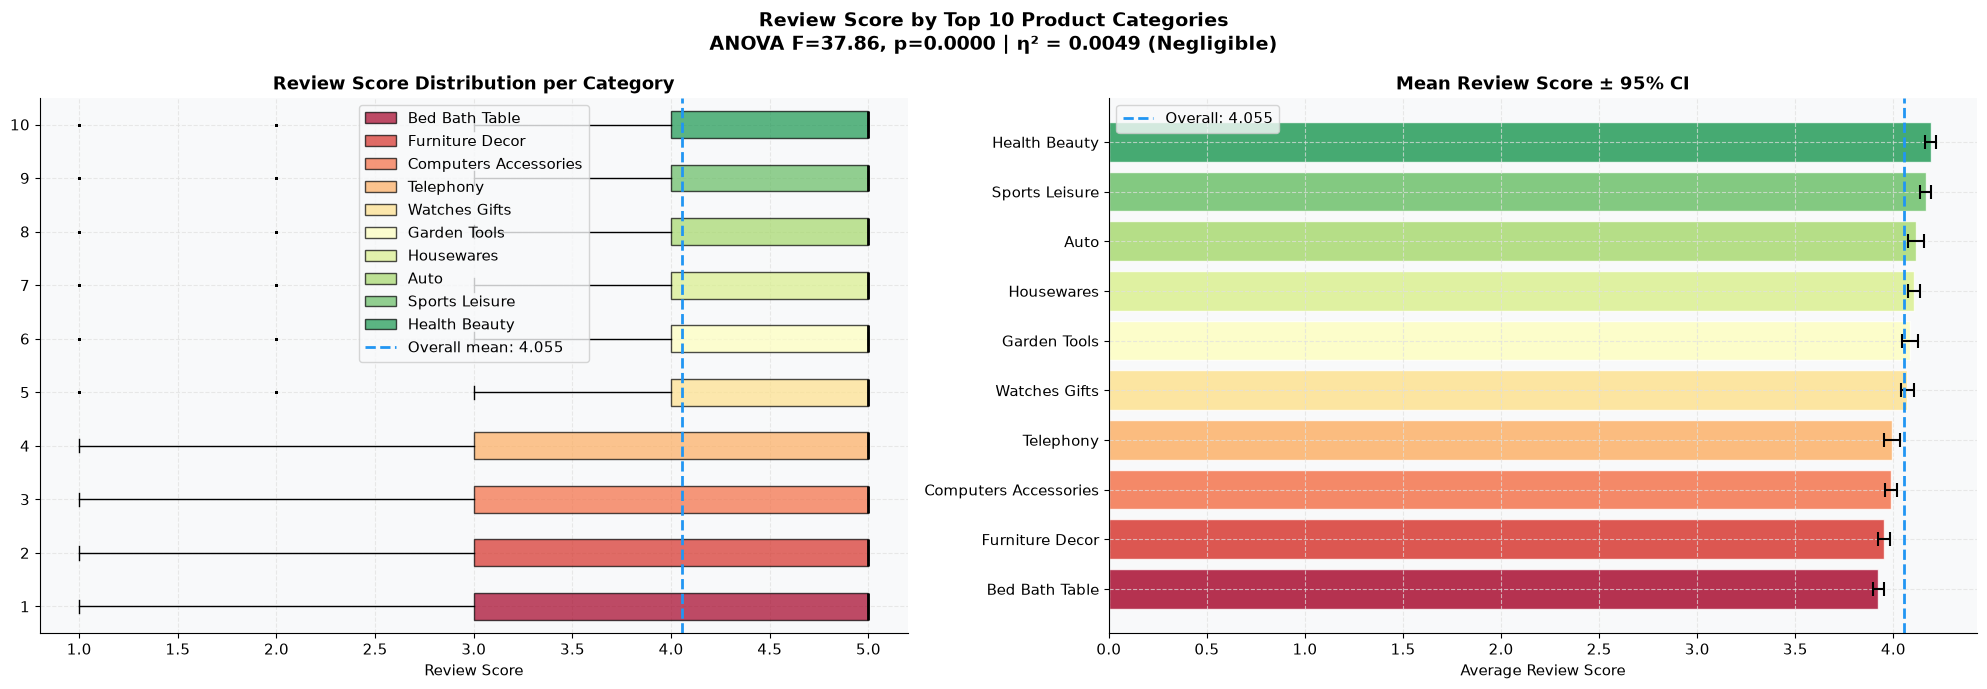


INTERPRETATION:
0.0049 => categories explain 0.49% of variance in review score


In [19]:
print("ANOVA + KRUSKAL-WALLIS: Review Score by Product Category")
print("=" * 70)

top_cats = (
    df_items[df_items['product_category_name_english'].notna()]
    .groupby('product_category_name_english')['order_id']
    .count()
    .nlargest(10)
    .index.tolist()
)

# Filter data
cat_review_df = df_items[
    df_items['product_category_name_english'].isin(top_cats) &
    df_items['review_score'].notna()
][['product_category_name_english', 'review_score']].copy()

cat_stats = cat_review_df.groupby('product_category_name_english')['review_score'].agg([
    'count', 'mean', 'median', 'std'
]).round(4).sort_values('mean', ascending=False)

print(f"\n{'Category':<40} {'n':>7} {'Mean':>7} {'Median':>8} {'Std':>7}")
print("-" * 70)
for cat, row in cat_stats.iterrows():
    cat_short = cat[:38]
    print(f"   {cat_short:<38} {row['count']:>7,.0f} "
          f"{row['mean']:>7.3f} {row['median']:>8.1f} {row['std']:>7.3f}")

# One-Way ANOVA
groups = [
    cat_review_df[cat_review_df['product_category_name_english'] == cat]
    ['review_score'].values
    for cat in top_cats
]

f_stat, anova_p = stats.f_oneway(*groups)

# Kruskal-Wallis (non-parametric alternative)
kw_stat, kw_p = stats.kruskal(*groups)

# Effect size
grand_mean = cat_review_df['review_score'].mean()
ss_between = sum(
    len(g) * (g.mean() - grand_mean)**2
    for g in groups
)
ss_total = sum((cat_review_df['review_score'] - grand_mean)**2)
eta_sq = ss_between / ss_total

def interpret_eta_sq(eta: float) -> str:
    """Interpretasi eta-squared effect size."""
    if eta < 0.01: return 'Negligible'
    elif eta < 0.06: return 'Small'
    elif eta < 0.14: return 'Medium'
    else: return 'Large'

print(f"\n STATISTICAL TEST RESULTS:")
print(f"\n   One-Way ANOVA:")
print(f" F-statistic: {f_stat:.4f}")
print(f" p-value: {anova_p:.6f}")
print(f" Significant: {anova_p < ALPHA}")

print(f"\n   Kruskal-Wallis (non-parametric confirmation):")
print(f" H-statistic: {kw_stat:.4f}")
print(f" p-value: {kw_p:.6f}")
print(f" Significant: {kw_p < ALPHA}")

print(f"\n   Effect Size (η²): {eta_sq:.6f}")
print(f"Magnitude: {interpret_eta_sq(eta_sq)}")

# Post-hoc (top vs bottom category)
best_cat  = cat_stats.index[0]
worst_cat = cat_stats.index[-1]
g_best = cat_review_df[cat_review_df['product_category_name_english'] == best_cat]['review_score']
g_worst = cat_review_df[cat_review_df['product_category_name_english'] == worst_cat]['review_score']
t_post, p_post = stats.mannwhitneyu(g_best, g_worst, alternative='two-sided')
d_post = cohens_d(g_best, g_worst)

print(f"\n   Post-hoc (Best vs Worst category):")
print(f" {best_cat[:35]} vs {worst_cat[:35]}")
print(f" Mean diff: {g_best.mean():.3f} vs {g_worst.mean():.3f}")
print(f" Mann-Whitney p: {p_post:.6f}")
print(f" Cohen's d: {d_post:.4f} ({interpret_cohens_d(d_post)})")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
fig.suptitle(
    f'Review Score by Top 10 Product Categories\n'
    f'ANOVA F={f_stat:.2f}, p={anova_p:.4f} | η² = {eta_sq:.4f} '
    f'({interpret_eta_sq(eta_sq)})',
    fontsize=14, fontweight='bold'
)

# Plot 1: Box plots per category
ax1 = axes[0]
cat_order = cat_stats.sort_values('mean').index.tolist()
groups_ordered = [
    cat_review_df[cat_review_df['product_category_name_english'] == cat]
    ['review_score'].values
    for cat in cat_order
]
labels_short = [c[:30].replace('_', ' ').title() for c in cat_order]

bp = ax1.boxplot(
    groups_ordered,
    label=labels_short,
    vert=False,
    patch_artist=True,
    medianprops=dict(color='black', linewidth=2),
    flierprops=dict(marker='.', markersize=2, alpha=0.3)
)
cmap = plt.cm.RdYlGn
colors_box = [cmap(i / len(groups_ordered))
              for i in range(len(groups_ordered))]
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax1.axvline(
    cat_review_df['review_score'].mean(),
    color=COLORS['primary'], linestyle='--', linewidth=2,
    label=f"Overall mean: {cat_review_df['review_score'].mean():.3f}"
)
ax1.set_xlabel('Review Score')
ax1.set_title('Review Score Distribution per Category')
ax1.legend()

# Plot 2: Mean & CI
ax2 = axes[1]
means_sorted = cat_stats.sort_values('mean', ascending=True)
y_pos = range(len(means_sorted))
errors = [
    1.96 * row['std'] / np.sqrt(row['count'])
    for _, row in means_sorted.iterrows()
]
cmap2 = plt.cm.RdYlGn
colors2 = [cmap2(i / len(means_sorted)) for i in range(len(means_sorted))]

ax2.barh(
    [c[:30].replace('_', ' ').title() for c in means_sorted.index],
    means_sorted['mean'],
    xerr=errors, capsize=5,
    color=colors2, alpha=0.8, edgecolor='white',
    error_kw=dict(linewidth=1.5, capthick=1.5)
)
ax2.axvline(
    cat_review_df['review_score'].mean(),
    color=COLORS['primary'], linestyle='--', linewidth=2,
    label=f"Overall: {cat_review_df['review_score'].mean():.3f}"
)
ax2.set_xlabel('Average Review Score')
ax2.set_title('Mean Review Score ± 95% CI')
ax2.legend()

plt.tight_layout()
# plt.savefig('../assets/statistical/05_anova_review_category.png')
plt.show()

print(f"\nINTERPRETATION:")
print(f"{eta_sq:.4f} => categories explain "
      f"{eta_sq*100:.2f}% of variance in review score")


Region                n    Mean   Median     Std     P90
-------------------------------------------------------
 Southeast      75,548    10.4      9.0     7.5    19.0
 South          15,853    13.8     12.0     7.9    24.0
 Center-West     6,469    14.7     13.0     7.6    24.0
 Northeast      10,000    19.2     17.0     9.4    32.0
 North           1,998    21.8     20.0    10.1    35.3

KRUSKAL-WALLIS RESULTS:
H-statistic: 16683.3941
p-value: 0.0000000000
Significant: True
η² (approx): 0.1518 (Large)

 Post-hoc Pairwise (Bonferroni corrected):
 Bonferroni: 0.05/10 = 0.0050

 Region A        Region B         Diff (days)    p-value   Sig
   ------------------------------------------------------------
   Southeast       South                   -3.0   0.000000  True
   Southeast       Center-West             -4.0   0.000000  True
   Southeast       Northeast               -8.0   0.000000  True
   Southeast       North                  -11.0   0.000000  True
   South           Center-W

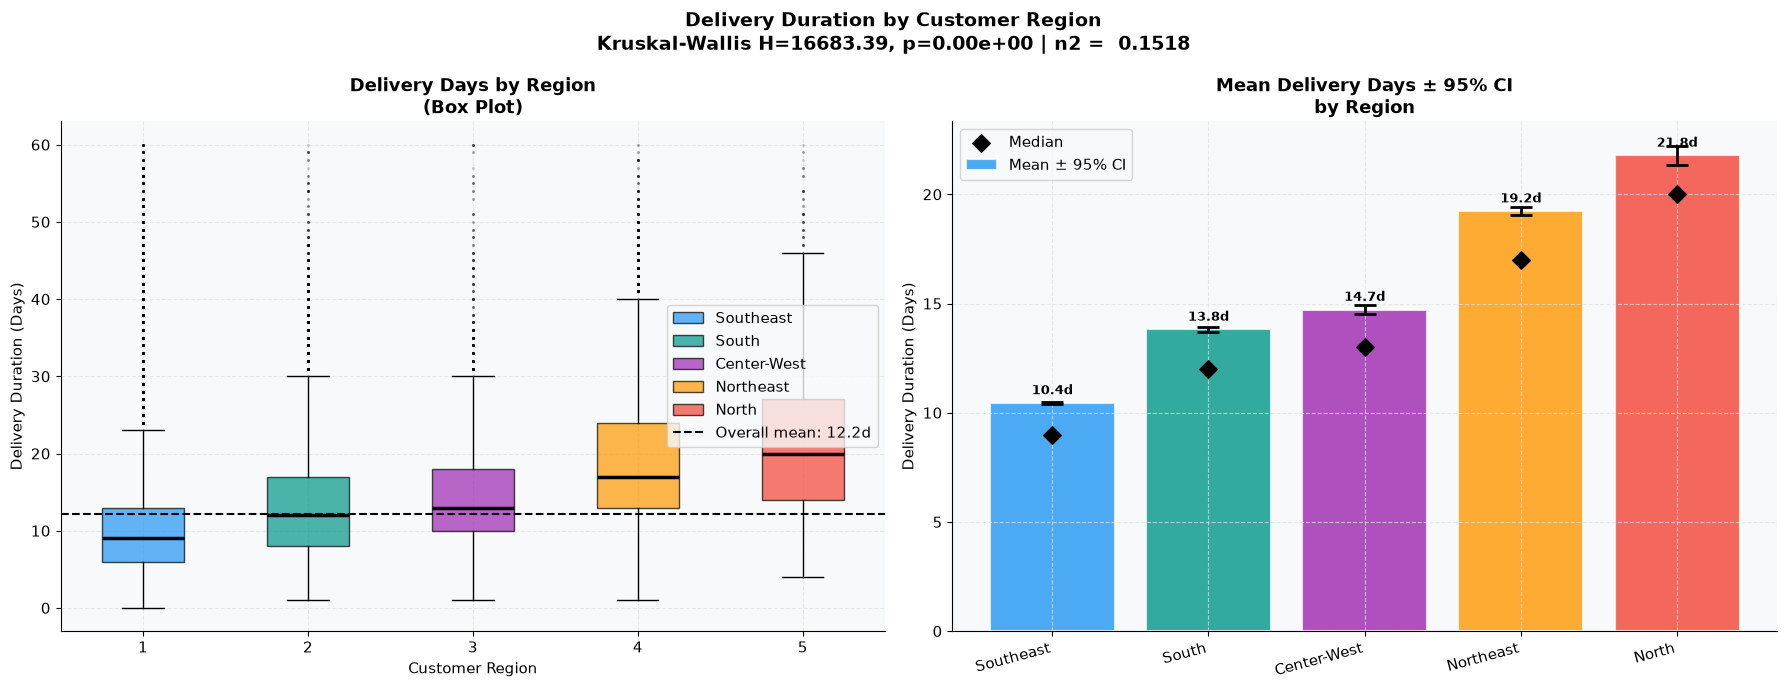

In [20]:
regions = ['Southeast', 'South', 'Center-West', 'Northeast', 'North']
delivery_col  = 'purchase_to_delivery_days'

region_groups = []
for region in regions:
    g = df_items[
        (df_items['customer_region'] == region) &
        df_items[delivery_col].notna() &
        (df_items[delivery_col] >= 0) &
        (df_items[delivery_col] <= 60)
    ][delivery_col]
    region_groups.append(g)

# Descriptive per region
print(f"\n{'Region':<15} {'n':>7} {'Mean':>7} {'Median':>8} {'Std':>7} {'P90':>7}")
print("-" * 55)
for region, g in zip(regions, region_groups):
    print(f" {region:<13} {len(g):>7,} {g.mean():>7.1f} "
          f"{g.median():>8.1f} {g.std():>7.1f} "
          f"{g.quantile(0.9):>7.1f}")

# Kruskal-Wallis
kw_stat, kw_p = stats.kruskal(*region_groups)

# Effect size
n_total = sum(len(g) for g in region_groups)
k = len(regions)
eta_sq_kw = (kw_stat - k + 1) / (n_total - k)

print(f"\nKRUSKAL-WALLIS RESULTS:")
print(f"H-statistic: {kw_stat:.4f}")
print(f"p-value: {kw_p:.10f}")
print(f"Significant: {kw_p < ALPHA}")
print(f"η² (approx): {eta_sq_kw:.4f} ({interpret_eta_sq(eta_sq_kw)})")

# Post-hoc: Pairwise Mann-Whitney dengan Bonferroni correction
from itertools import combinations

print(f"\n Post-hoc Pairwise (Bonferroni corrected):")
pairs = list(combinations(range(len(regions)), 2))
alpha_bonferroni = ALPHA / len(pairs)
print(f" Bonferroni: {ALPHA}/{len(pairs)} = {alpha_bonferroni:.4f}")
print(f"\n {'Region A':<15} {'Region B':<15} "
      f"{'Diff (days)':>12} {'p-value':>10} {'Sig':>5}")
print("   " + "-" * 60)

posthoc_results = []
for i, j in pairs:
    r_a, r_b = regions[i], regions[j]
    g_a, g_b = region_groups[i], region_groups[j]
    _, p_pair = stats.mannwhitneyu(g_a, g_b, alternative='two-sided')
    diff = g_a.median() - g_b.median()
    sig  = 'True' if p_pair < alpha_bonferroni else '  '
    posthoc_results.append({'Region A': r_a, 'Region B': r_b,
                             'p': p_pair, 'diff': diff})
    print(f"   {r_a:<15} {r_b:<15} "
          f"{diff:>+12.1f} {p_pair:>10.6f} {sig:>5}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle(
    f'Delivery Duration by Customer Region\n'
    f'Kruskal-Wallis H={kw_stat:.2f}, p={kw_p:.2e} | n2 =  {eta_sq_kw:.4f}',
    fontsize=14, fontweight='bold'
)

region_colors_map = {
    'Southeast': COLORS['primary'],
    'South': COLORS['teal'],
    'Center-West': COLORS['purple'],
    'Northeast': COLORS['secondary'],
    'North': COLORS['danger'],
}

# Plot 1: Box plots
ax1 = axes[0]
bp = ax1.boxplot(
    region_groups,
    label=regions,
    patch_artist=True,
    medianprops=dict(color='black', linewidth=2.5),
    flierprops=dict(marker='.', markersize=2, alpha=0.2)
)
for patch, region in zip(bp['boxes'], regions):
    patch.set_facecolor(region_colors_map[region])
    patch.set_alpha(0.7)

ax1.set_xlabel('Customer Region')
ax1.set_ylabel('Delivery Duration (Days)')
ax1.set_title('Delivery Days by Region\n(Box Plot)')
ax1.axhline(
    np.concatenate(region_groups).mean(),
    color='black', linestyle='--', linewidth=1.5,
    label=f'Overall mean: {np.concatenate(region_groups).mean():.1f}d'
)
ax1.legend()

# Plot 2: Mean + CI
ax2 = axes[1]
means_r = [g.mean() for g in region_groups]
errors_r = [1.96 * stats.sem(g) for g in region_groups]
medians_r = [g.median() for g in region_groups]

x_r = np.arange(len(regions))
bars = ax2.bar(
    x_r, means_r,
    yerr=errors_r,
    color=[region_colors_map[r] for r in regions],
    alpha=0.8, capsize=8, edgecolor='white', linewidth=1.5,
    error_kw=dict(linewidth=2, capthick=2),
    label='Mean ± 95% CI'
)
ax2.scatter(
    x_r, medians_r,
    color='black', zorder=5, s=80,
    marker='D', label='Median'
)
for bar, mean, median in zip(bars, means_r, medians_r):
    ax2.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.4,
        f'{mean:.1f}d', ha='center', fontsize=9, fontweight='bold'
    )

ax2.set_xticks(x_r)
ax2.set_xticklabels(regions, rotation=15, ha='right')
ax2.set_ylabel('Delivery Duration (Days)')
ax2.set_title('Mean Delivery Days ± 95% CI\nby Region')
ax2.legend()

plt.tight_layout()
# plt.savefig('../assets/statistical/06_kruskal_delivery_region.png')
plt.show()


Contingency Table (Observed Frequencies):
primary_payment_type  boleto  credit_card  debit_card  voucher
customer_region                                               
Center-West             1390         4940          61       87
North                    453         1502          28       29
Northeast               1871         7905         128      166
South                   3805        11686         188      189
Southeast              14842        58498        1196     1142

CHI-SQUARE TEST RESULTS:
 Chi² statistic: 217.8526
 Degrees of freedom: 12
 p-value: 0.0000000000
 Significant: True

 Effect Size (Cramér's V): 0.0257
   Magnitude: Negligible

 Assumption check:
   Min expected frequency: 29.26 ≥ 5


Contingency Table (Row %):
primary_payment_type  boleto  credit_card  debit_card  voucher
customer_region                                               
Center-West             21.5         76.3         0.9      1.3
North                   22.5         74.7         1.4      1.4


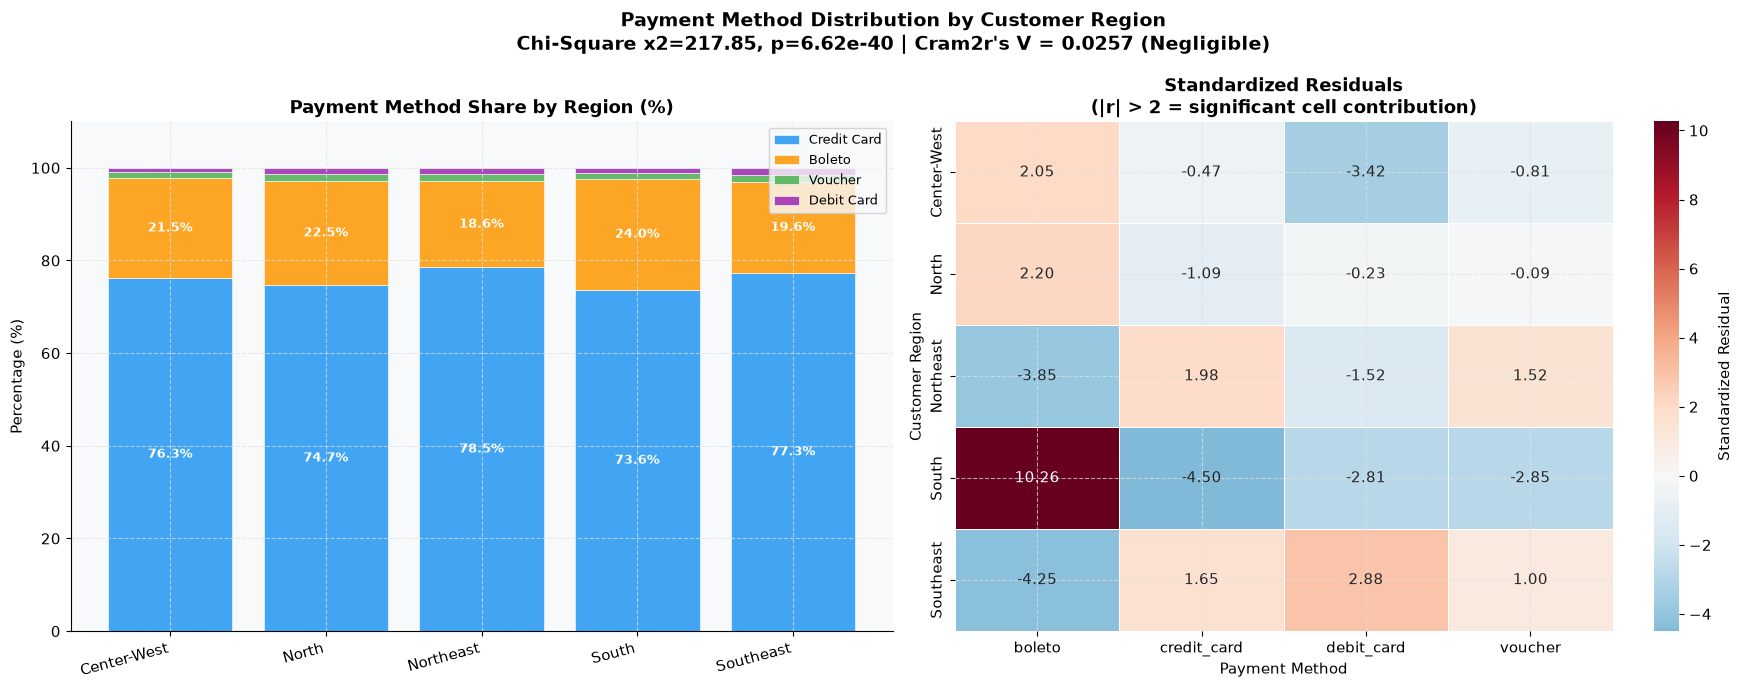

In [21]:
main_payments = ['credit_card', 'boleto', 'voucher', 'debit_card']
chi_df = df_items[
    df_items['primary_payment_type'].isin(main_payments) &
    df_items['customer_region'].notna() &
    (df_items['customer_region'] != 'Unknown')
][['primary_payment_type', 'customer_region']].copy()

contingency = pd.crosstab(
    chi_df['customer_region'],
    chi_df['primary_payment_type']
)

print("\nContingency Table (Observed Frequencies):")
print(contingency.to_string())

# Chi-Square Test
chi2, chi_p, dof, expected = stats.chi2_contingency(contingency)

# Effect size: Cramer's V
n = contingency.values.sum()
min_dim = min(contingency.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))

def interpret_cramers_v(v: float) -> str:
    """Interpretasi Cramer's V effect size."""
    if v < 0.10:   return 'Negligible'
    elif v < 0.30: return 'Small'
    elif v < 0.50: return 'Medium'
    else: return 'Large'

# Check expected frequencies
min_expected = expected.min()
chi_assumption_met = min_expected >= 5

print(f"\nCHI-SQUARE TEST RESULTS:")
print(f" Chi² statistic: {chi2:.4f}")
print(f" Degrees of freedom: {dof}")
print(f" p-value: {chi_p:.10f}")
print(f" Significant: {chi_p < ALPHA}")
print(f"\n Effect Size (Cramér's V): {cramers_v:.4f}")
print(f"   Magnitude: {interpret_cramers_v(cramers_v)}")
print(f"\n Assumption check:")
print(f"   Min expected frequency: {min_expected:.2f} "
      f"{'≥ 5' if chi_assumption_met else '< 5 (violated!)'}")

# Percentage table
contingency_pct = contingency.div(contingency.sum(axis=1), axis=0) * 100

print("\n\nContingency Table (Row %):")
print(contingency_pct.round(1).to_string())

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle(
    f'Payment Method Distribution by Customer Region\n'
    f'Chi-Square x2={chi2:.2f}, p={chi_p:.2e} | '
    f"Cram2r's V = {cramers_v:.4f} ({interpret_cramers_v(cramers_v)})",
    fontsize=14, fontweight='bold'
)

# Plot 1: Stacked bar (% per region)
ax1 = axes[0]
payment_colors = {
    'credit_card': COLORS['primary'],
    'boleto': COLORS['secondary'],
    'voucher': COLORS['success'],
    'debit_card': COLORS['purple'],
}

regions_plot = contingency_pct.index.tolist()
x_chi = np.arange(len(regions_plot))
bottoms_chi = np.zeros(len(regions_plot))

for payment in main_payments:
    if payment in contingency_pct.columns:
        vals = contingency_pct[payment].values
        bars = ax1.bar(
            x_chi, vals, bottom=bottoms_chi,
            color=payment_colors[payment], alpha=0.85,
            edgecolor='white', linewidth=0.5,
            label=payment.replace('_', ' ').title()
        )
        for i, (v, b) in enumerate(zip(vals, bottoms_chi)):
            if v > 5:
                ax1.text(i, b + v/2, f'{v:.1f}%',
                         ha='center', va='center',
                         fontsize=9, color='white', fontweight='bold')
        bottoms_chi += vals

ax1.set_xticks(x_chi)
ax1.set_xticklabels(regions_plot, rotation=15, ha='right')
ax1.set_ylabel('Percentage (%)')
ax1.set_title('Payment Method Share by Region (%)')
ax1.legend(loc='upper right', fontsize=9)
ax1.set_ylim(0, 110)

# Plot 2: Heatmap of normalized residuals (contribution to chi2)
ax2 = axes[1]
observed = contingency.values
residuals = (observed - expected) / np.sqrt(expected)

residual_df = pd.DataFrame(
    residuals,
    index=contingency.index,
    columns=contingency.columns
)
sns.heatmap(
    residual_df,
    ax=ax2,
    cmap='RdBu_r',
    center=0,
    annot=True,
    fmt='.2f',
    linewidths=0.5,
    cbar_kws={'label': 'Standardized Residual'}
)
ax2.set_title('Standardized Residuals\n(|r| > 2 = significant cell contribution)')
ax2.set_xlabel('Payment Method')
ax2.set_ylabel('Customer Region')

plt.tight_layout()
# plt.savefig('../assets/statistical/07_chisquare_payment_region.png')
plt.show()